In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ecommerce_customer_data_custom_ratios.csv to ecommerce_customer_data_custom_ratios.csv


In [ ]:

import pandas as pd

df = pd.read_csv('ecommerce_customer_data_custom_ratios.csv')

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (250000, 13)


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1


In [ ]:
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
print(df.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Customer ID            250000 non-null  int64  
 1   Purchase Date          250000 non-null  object 
 2   Product Category       250000 non-null  object 
 3   Product Price          250000 non-null  int64  
 4   Quantity               250000 non-null  int64  
 5   Total Purchase Amount  250000 non-null  int64  
 6   Payment Method         250000 non-null  object 
 7   Customer Age           250000 non-null  int64  
 8   Returns                202404 non-null  float64
 9   Customer Name          250000 non-null  object 
 10  Age                    250000 non-null  int64  
 11  Gender                 250000 non-null  object 
 12  Churn                  250000 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 24.8+ MB
None

Missing Values:
Customer 

In [ ]:
# Fill missing values in Returns column

df['Returns'] = df['Returns'].fillna(0)

# Convert Purchase Date to datetime

df['Purchase Date'] = pd.to_datetime(df['Purchase Date'])

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Customer ID              0
Purchase Date            0
Product Category         0
Product Price            0
Quantity                 0
Total Purchase Amount    0
Payment Method           0
Customer Age             0
Returns                  0
Customer Name            0
Age                      0
Gender                   0
Churn                    0
dtype: int64


In [ ]:
customer_summary = df.groupby('Customer ID').agg({
    'Total Purchase Amount':'sum',
    'Quantity':'sum'
}).reset_index()

customer_summary['Segment'] = pd.qcut(
    customer_summary['Total Purchase Amount'],
    q=3,
    labels=['Low Value','Medium Value','High Value']
)

customer_summary.head()

,Customer ID,Total Purchase Amount,Quantity,Segment
0,1,3491,5,Low Value
1,2,7988,8,Low Value
2,3,22587,23,High Value
3,4,8715,9,Low Value
4,5,12524,33,Medium Value


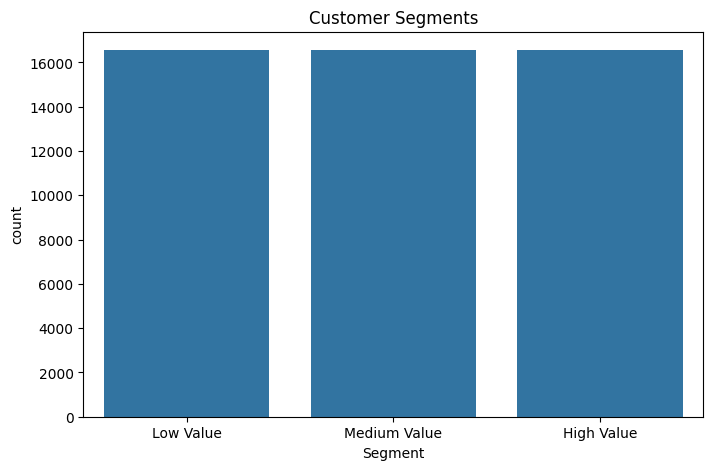

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.countplot(
    x='Segment',
    data=customer_summary,
    order=['Low Value','Medium Value','High Value']
)

plt.title('Customer Segments')
plt.show()

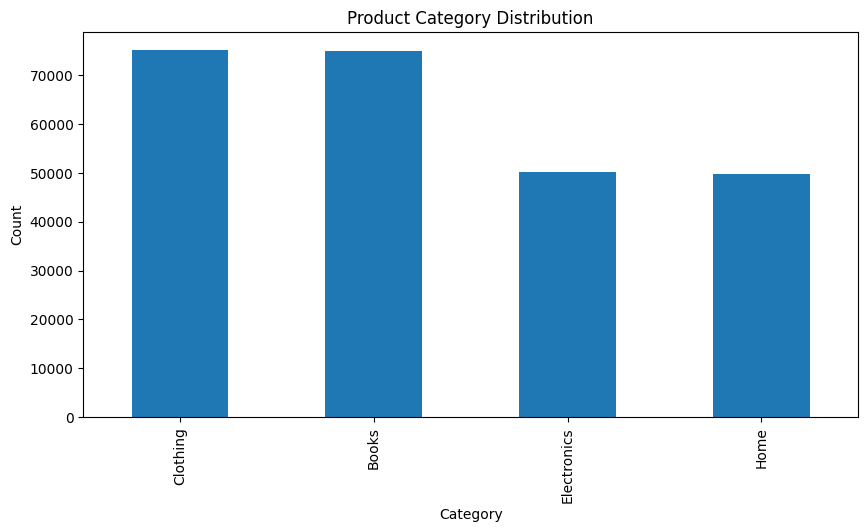

In [ ]:
plt.figure(figsize=(10,5))

df['Product Category'].value_counts().plot(kind='bar')

plt.title('Product Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')

plt.show()

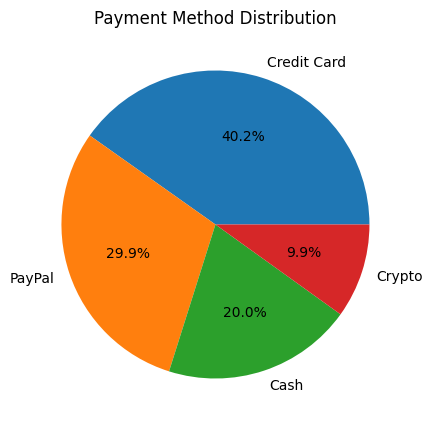

In [ ]:
plt.figure(figsize=(8,5))

df['Payment Method'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.ylabel('')
plt.title('Payment Method Distribution')

plt.show()

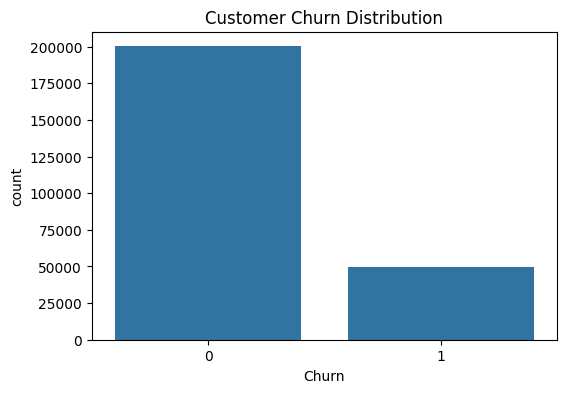

Churn
0    200126
1     49874
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='Churn',
    data=df
)

plt.title('Customer Churn Distribution')

plt.show()

print(df['Churn'].value_counts())

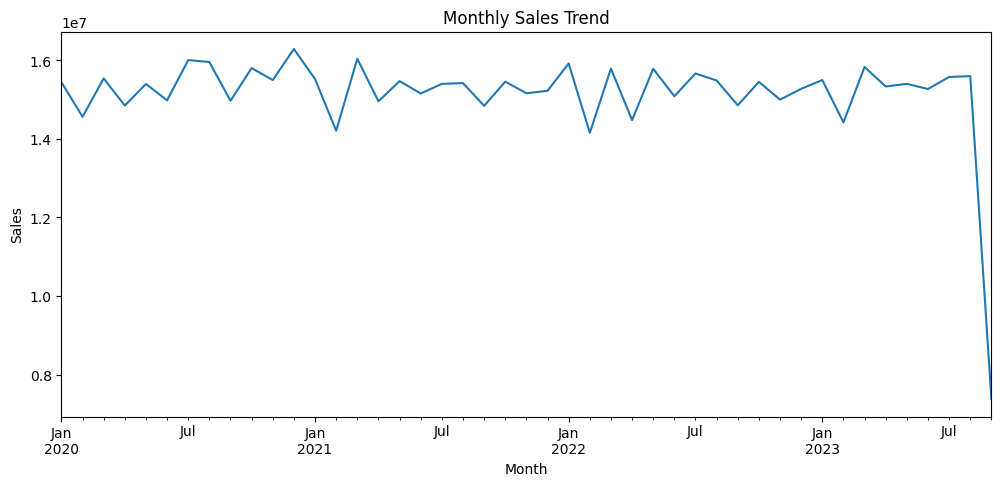

In [ ]:
df['Month'] = df['Purchase Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Total Purchase Amount'].sum()

monthly_sales.plot(
    figsize=(12,5)
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')

plt.show()